<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">12 · Named-entity recognition & adverse-event detection</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 5: token classification on visit notes, and a rematch against the notebook-07 side-effect detector</p>

| | |
|---|---|
| **Task A · NER** | tag every **DRUG**, **ADVERSE_EVENT** and **DOSE** in a visit note (BIO tags from notebook 09) |
| **Task B · ADE** | does a sentence describe an adverse drug event? ADE Corpus v2, **the same split as notebook 07** |
| **Model** | `BiomedBERT`, fine-tuned on CPU (NER 29 min, ADE ~2 h) · code `src/glp1_intel/models/ner_ade.py` |
| **Outputs** | `models/visit_note_ner_biomedbert` · `models/ade_sentence_biomedbert` · metrics in `reports/evaluation/nb12_*.json` |
| **Concepts** | token classification · BIO tags · sub-word label alignment · entity-level vs token-level F1 (seqeval) · precision–recall trade-off · thresholds for safety · label coverage |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · From labelling notes to labelling words</b>

Notebook 11 gave **one label per note**. Here we go finer:
- **Sequence classification** (notebook 11, task B here): text → one label
- **Token classification / NER** (task A): text → one label **per token**, e.g. `Ozempic → B-DRUG`, `nausea → B-ADVERSE_EVENT`

In the product, NER **highlights** the drugs and side effects inside a rep's note (🔵 competitor, 🔴 side effect), and the ADE classifier decides which sentences a pharmacovigilance reviewer must read.

</div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline, logging as hf_logging

from glp1_intel import viz
from glp1_intel.viz import TEXT, TEXT_2, MUTED, subtitle
from glp1_intel.notebook_style import show
from glp1_intel.models import ner_ade as N
from glp1_intel.nlp import classical as C

hf_logging.set_verbosity_error()
ner_res, ade_res = N.result("ner"), N.result("ade")
base = json.loads((C.EVAL_DIR / "nb07_tfidf_baselines.json").read_text())
VIOLET, TEAL, PEACH = "#7C5CFF", "#0EA5A0", "#FF8A65"
print("NER results:", "loaded" if ner_res else "missing", "· ADE results:", "loaded" if ade_res else "missing")

NER results: loaded · ADE results: loaded


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## A · NER on visit notes

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Aligning word labels to sub-word tokens</b>

WordPiece splits words into pieces (`Zepbound → ze ##pb ##ound`), but our labels are per **word**. Standard fix:
- the **first** sub-token of each word gets the word's tag (`ze → B-DRUG`)
- the other pieces get **−100**, which PyTorch's loss **ignores**
- `[CLS]`, `[SEP]` and padding also get −100

At prediction time we read the tag of each word's first sub-token.

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Entity-level F1 (seqeval)</b>

- **Token-level accuracy** is misleading: 95% of tokens are `O`, so predicting `O` everywhere looks great.
- **Entity-level F1** (the `seqeval` library) counts an entity as correct only if its **type and full span** match exactly: `injection site pain` must be found as one ADVERSE_EVENT, not two pieces.

</div>

In [2]:
rep = ner_res["report"]
rows = [{"entity": k, "precision": v["precision"], "recall": v["recall"], "f1": v["f1-score"], "test entities": int(v["support"])}
        for k, v in rep.items() if k in ("DRUG", "ADVERSE_EVENT", "DOSE", "micro avg", "macro avg")]
show(pd.DataFrame(rows), f"Entity-level results on 158 test notes (overall micro-F1 {ner_res['test_entity_f1']:.3f})", precision=3)
print("Validation entity-F1 by epoch:", [round(c["val_entity_f1"], 3) for c in ner_res["curve"]])

Validation entity-F1 by epoch: [0.887, 0.977, 0.989, 0.991, 0.989]


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **DRUG ≈ 1.00**: brand and generic names are distinctive words, easy to learn.
- **ADVERSE_EVENT ≈ 0.95**: strong, including multi-word spans like *injection site pain*.
- **DOSE ≈ 0.6**, but on only **5** test entities: reps rarely write doses (notebook 09), so the model barely saw any. With 5 examples the score is **too noisy to trust** either way; more dose-bearing notes are needed.
- The **macro average** (≈0.86) is pulled down by DOSE, while the **micro average** (≈0.98) is dominated by the many drug mentions. Always report which one you use.
- Validation F1 is near its peak after 3 epochs.

</div>

In [3]:
errs = []
for ex in ner_res["examples"]:
    for tok, t, p in zip(ex["tokens"], ex["true"], ex["pred"]):
        if t != p:
            errs.append({"token": tok, "label (rule-based)": t, "model prediction": p, "note snippet": " ".join(ex["tokens"])[:120]})
show(pd.DataFrame(errs), "Disagreements in 20 test notes")

token,label (rule-based),model prediction,note snippet
asthma,O,B-ADVERSE_EVENT,"Quick visit w / Dr . , family practice . Discussed Rybelsus . HCP not sold , thinks Foundayo works just as well or bette"
injection,O,B-ADVERSE_EVENT,"Met HCP , discussed Zepbound . NPs ok w / it , patient like doc's choice . One pt had redness at injection site . Docs s"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The model tags words like **asthma** or **injection** as side effects although our labels say `O`.
Our labels came from a **fixed word list** (notebook 09), which doesn't contain *asthma*; the model learned the *concept* of a symptom and generalised beyond the list.
So some "false positives" are really **gaps in the labels**. The same lesson as notebook 11: a strong model's errors are a good way to audit the data.

</div>

In [4]:
saved = N.MODEL_DIR / "visit_note_ner_biomedbert"
tagger = pipeline("token-classification", model=str(saved), aggregation_strategy="first")
for note in ["Dr. mentioned 2 pts on Ozempic 1 mg had bad constipation, switched one to Mounjaro 5 mg.",
             "HCP prefers Foundayo for needle-phobic pts, worried about nausea and gallbladder issues in elderly."]:
    ents = [(e["word"], e["entity_group"], round(float(e["score"]), 2)) for e in tagger(note)]
    print(note, "\n   →", ents, "\n")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Dr. mentioned 2 pts on Ozempic 1 mg had bad constipation, switched one to Mounjaro 5 mg. 
   → [('ozempic', 'DRUG', 1.0), ('1 mg', 'DOSE', 0.65), ('constipation', 'ADVERSE_EVENT', 1.0), ('mounjaro', 'DRUG', 1.0), ('5 mg', 'DOSE', 0.67)] 

HCP prefers Foundayo for needle-phobic pts, worried about nausea and gallbladder issues in elderly. 
   → [('foundayo', 'DRUG', 1.0), ('nausea', 'ADVERSE_EVENT', 1.0), ('gallbladder', 'ADVERSE_EVENT', 0.91)] 



<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- On brand-new notes the tagger finds the drugs and side effects with confidence ≈ 1.0, and the doses (`1 mg`, `5 mg`) too, but with only ≈ 0.65 confidence: the DOSE weakness from the table shows up again.
- In note 2 it tags **gallbladder** but not the word *issues*: the span is shorter than a human would mark. Span boundaries are the usual weak spot of NER.
- The rep view will use this to **highlight** text, and the analyst dashboard to **count** side-effect and competitor mentions per doctor.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## B · ADE detection: rematch against notebook 07

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · A controlled comparison</b>

Same data, **same deduplicated split**, same safety rule (pick the threshold reaching **≥ 90% recall on validation**), different model:
TF-IDF + Logistic Regression (notebook 07) vs fine-tuned **BiomedBERT**. Only the model changes, so the comparison is fair.

</div>

In [5]:
tf_def, tf_r90 = base["test_logreg_default_threshold"], base["test_logreg_recall90_threshold"]
bb_def, bb_r90 = ade_res["test_default"], ade_res["test_recall90"]
cols = ["precision", "recall", "f1", "pr_auc", "roc_auc", "tp", "fp", "fn"]
comp = pd.DataFrame([
    {"model": "TF-IDF + LogReg (nb 07)", "threshold": "0.50", **{c: tf_def[c] for c in cols}},
    {"model": "BiomedBERT", "threshold": "0.50", **{c: bb_def[c] for c in cols}},
    {"model": "TF-IDF + LogReg (nb 07)", "threshold": f"{tf_r90['threshold']:.2f} (≥90% recall)", **{c: tf_r90[c] for c in cols}},
    {"model": "BiomedBERT", "threshold": f"{bb_r90['threshold']:.2f} (≥90% recall)", **{c: bb_r90[c] for c in cols}},
])
show(comp, "Test set (3,135 sentences, 641 ADEs): same split, same policy", precision=3)

model,threshold,precision,recall,f1,pr_auc,roc_auc,tp,fp,fn
TF-IDF + LogReg (nb 07),0.50,0.649,0.730,0.687,0.750,0.916,468,253,173
BiomedBERT,0.50,0.883,0.927,0.904,0.957,0.989,594,79,47
TF-IDF + LogReg (nb 07),0.25 (≥90% recall),0.466,0.917,0.618,0.750,0.916,588,673,53
BiomedBERT,0.58 (≥90% recall),0.890,0.917,0.903,0.957,0.989,588,73,53


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **F1 0.69 → 0.90** and **PR-AUC 0.75 → 0.96**: a large, clear improvement.
- The safety view is the most telling: at the **same ~92% recall**, TF-IDF raised **673 false alarms**, BiomedBERT only **73**. A reviewer would read about **9× fewer** wrong flags to catch the same side effects.
- BiomedBERT's chosen threshold sits near 0.58 (vs 0.25 for TF-IDF): its probabilities are better separated, so it doesn't need to lower the bar to reach high recall.

</div>

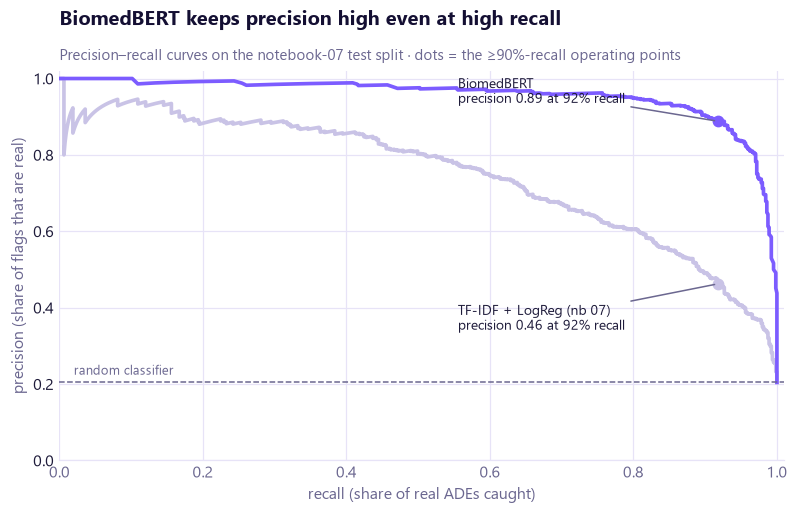

In [6]:
from sklearn.metrics import precision_recall_curve
train_df, _, test_df = C.split(C.load_ade())
tfidf_model = C.pipelines()["Logistic Regression (TF-IDF)"].fit(train_df["text"], train_df["label"])
tf_scores = C.scores(tfidf_model, test_df["text"])
bb_scores = np.array(ade_res["test_scores"])

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for scores, name, color in [(tf_scores, "TF-IDF + LogReg (nb 07)", MUTED), (bb_scores, "BiomedBERT", VIOLET)]:
    p, r, _ = precision_recall_curve(test_df["label"], scores)
    ax.plot(r, p, color=color, lw=2.4)
    i = np.argmin(np.abs(r - 0.917))
    ax.scatter([r[i]], [p[i]], color=color, s=45, zorder=3)
    ax.annotate(f"{name}\nprecision {p[i]:.2f} at 92% recall", (r[i], p[i]), xytext=(-170, -30 if color == MUTED else 12),
                textcoords="offset points", fontsize=9, color=TEXT, arrowprops=dict(arrowstyle="-", color=TEXT_2))
ax.axhline(test_df["label"].mean(), color=TEXT_2, lw=1, ls="--")
ax.text(0.02, test_df["label"].mean() + 0.02, "random classifier", fontsize=8.5, color=TEXT_2)
ax.set(xlabel="recall (share of real ADEs caught)", ylabel="precision (share of flags that are real)", xlim=(0, 1.01), ylim=(0, 1.02))
ax.grid(axis="y")
ax.set_title("BiomedBERT keeps precision high even at high recall")
subtitle(ax, "Precision–recall curves on the notebook-07 test split · dots = the ≥90%-recall operating points")
viz.save(fig, "12_1_ade_pr_comparison")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The BiomedBERT curve stays near the top almost all the way to the right: it can catch nearly every ADE before precision collapses. The TF-IDF curve bends down early, which is the trade-off we accepted in notebook 07.

</div>

In [7]:
test_df = test_df.assign(tfidf=tf_scores, biomedbert=bb_scores)
fixed = test_df[(test_df["label"] == 1) & (test_df["tfidf"] < tf_r90["threshold"]) & (test_df["biomedbert"] >= bb_r90["threshold"])]
display(show(fixed[["tfidf", "biomedbert", "text"]].head(5), "Real ADEs that TF-IDF missed and BiomedBERT caught", precision=2))
missed = test_df[(test_df["label"] == 1) & (test_df["biomedbert"] < bb_r90["threshold"])].nsmallest(5, "biomedbert")
show(missed[["biomedbert", "text"]], "ADEs BiomedBERT still misses (lowest scores)", precision=2)

tfidf,biomedbert,text
0.25,0.97,"Renal failure appeared 8 to 17 days after beginning gentamicin therapy and was characterized by creatinine clearances 4 to 10 ml/min, urine to plasma creatinine ratios less than 20, urinary sodium concentrations 16 to 60 mEq/liter, proteinuria, and cylindruria."
0.21,0.98,"In three of these patients the infection was clinically unsuspected; in the fourth, cutaneous herpes zoster developed after administration of 300 mg of cytarabine daily for the preceding five days."
0.17,0.89,"A 33-year-old man with a history of recreational benztropine abuse presented to the emergency department with confusion, abdominal pain, and distention."
0.21,0.95,We describe two patients with aspergillus arthritis of the knee joint following fludarabine-based non-myeloablative stem cell transplantation.
0.21,0.98,"Benzocaine, an ester-type local anesthetic, was believed responsible for apparent methemoglobinemia in a cat."


biomedbert,text
0.00,The patient developed occipital infarcts and was found to have extremely elevated levels of PPA in his blood and dialysis fluid.
0.00,"Two patients with imminent gangrene of the extremities caused by ergot-induced arteriospasm underwent mechanical dilatation of the arteries when conventional measures such as anticoagulation, vasodilation, and sympathetic blockade produced no improvement."
0.00,We describe 2 children with cerebral palsy who suffered significant morbidity immediately after treatment with hyperbaric oxygen.
0.00,The sulfonamides are the best verified drug-trigger for erythema multiforme and Stevens-Johnson syndrome.
0.00,Generalized maculopapular and papular purpuric eruptions are perhaps the most common thionamide-induced reactions.


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The ADEs TF-IDF missed score ≈ 0.2, **just under** its 0.25 threshold: long sentences where the cue words (*after*, *following*) are diluted by many other words. BiomedBERT reads them in context and is confident (≈ 0.9+).
- BiomedBERT's misses are **confident** (score ≈ 0.00), and of two kinds: **general statements about a drug class** (*"sulfonamides are the best verified drug-trigger…"*, *"…the most common thionamide-induced reactions"*) rather than a patient case, and cases with an **unusual cause** (PPA, hyperbaric oxygen). The labelling of general statements is arguably inconsistent in ADE Corpus; either way, high F1 does not mean no confident mistakes.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## C · Summary

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. **NER labels are rule-based** (lexicon matching), so the model is evaluated against an imperfect reference that misses unusual wording.
2. **DOSE has too few examples** (5 in test) for a reliable score.
3. **ADE Corpus is case-report English** from older literature; visit notes and modern GLP-1 text differ (domain shift, notebook 07). Validate on real target text before relying on it.
4. These models **flag text for human review**. They are not a pharmacovigilance or compliance system.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** a visit-note NER model (entity F1 ≈ 0.98; DRUG ≈ 1.00, ADVERSE_EVENT ≈ 0.95) and an ADE sentence detector that beats the TF-IDF baseline decisively (F1 0.69 → 0.90; ~9× fewer false alarms at 92% recall). Both are saved for the rep view.
**Next:** Level 6: **sentence embeddings and vector search** (notebook 13), the retrieval half of RAG.

**Interview questions you can now answer**
- *What is NER and how is it trained?* Token classification with BIO tags; labels go on each word's first sub-token, the rest get −100.
- *Why entity-level F1 instead of token accuracy?* Most tokens are `O`; seqeval only credits exact type + span.
- *Micro vs macro F1 for NER?* Micro is dominated by frequent entities (drugs); macro exposes weak rare ones (doses).
- *How did you compare the transformer fairly with TF-IDF?* Same data split, same threshold policy, same metrics: only the model changed.
- *Why report false alarms at fixed recall?* It translates model quality into reviewer workload: 673 vs 73 wrong flags.
- *What did the model's "false positives" teach you?* That rule-based labels miss real side effects (e.g. asthma): models can audit their own training data.

</div>